# High-Frequency Words in Grade-School Math Word Problems

**Joao De Oliveira**

This notebook answers the seven questions of the High Frequency Words assignment using a math education corpus: **GSM8K**, a collection of grade-school math word problems and their worked solutions. As a math teacher, I believe that one of the skills that students have been struggling more and more with time, is text interpretation (knowing what they are being asked to do or understanding the meaning of keywords).

## 0. Setup

In [11]:
import re, json, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

for pkg, path in [("brown", "corpora/brown"), ("stopwords", "corpora/stopwords")]:
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(pkg, quiet=True)

from nltk.corpus import brown, stopwords
STOP = set(stopwords.words("english"))

## 1. Choose a corpus of interest
I chose **[GSM8K](https://github.com/openai/grade-school-math)** (Cobbe et al., 2021), a set of 8,792 grade-school math word problems. Human problem writers wrote each problem together with a step-by-step solution in natural language. The problems take 2 to 8 steps of basic arithmetic (addition, subtraction, multiplication, division, fractions and percentages), the level of upper elementary and middle school math.

As a math teacher, I find this corpus interesting because students struggle with word problems due to their incapcity to read and interpret English, which students have to learn to read alongside the math itself. The corpus has two parts, and I analyze both together (and compare them at the end):
- **Questions:** the word problems as a student would read them.
- **Solutions:** the worked explanations, the way a teacher would write them on the board.

In [12]:
URL = "https://raw.githubusercontent.com/openai/grade-school-math/master/grade_school_math/data/{}.jsonl"
rows = []
for split in ["train", "test"]:
    with urllib.request.urlopen(URL.format(split)) as f:
        rows += [json.loads(line) for line in f.read().decode("utf-8").splitlines()]
problems = pd.DataFrame(rows)

def clean_solution(s):
    s = re.sub(r"<<.*?>>", "", s)          # remove calculator annotations
    s = re.sub(r"####.*$", "", s)          # remove the final answer line
    return s

problems["solution"] = problems["answer"].apply(clean_solution)
print(f"Problems: {len(problems):,}")
print("\nExample question:\n", problems.question[0])
print("\nExample solution (cleaned):\n", problems.solution[0])

Problems: 8,792

Example question:
 Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?

Example solution (cleaned):
 Natalia sold 48/2 = 24 clips in May.
Natalia sold 48+24 = 72 clips altogether in April and May.



## 2. How many unique words are in the corpus?
**My definition of a word:** a sequence of letters, **lowercased**, that may contain an internal apostrophe ("doesn't" stays one word), with the possessive **'s** removed.

**Numbers are not words.** In this corpus, numbers are the "data" of each problem rather than its language, and every problem uses different ones, so counting "48" and "72" as words would inflate the vocabulary with thousands of one-off values. I also convert the multiplication sign "x" used in the solutions ("0.2 x 50", "8 games x 2 hours") into an operator, so that it doesn't count as the word "x". When "x" is an algebra variable ("let x be the number of...", "x + 278 = 536"), it stays a word.

In [13]:
def tokenize(text):
    text = text.lower().replace("\u2019", "'")
    # multiplication signs but x in algebra stays
    text = re.sub(r"(?<=[\d)$%])\s*x\s*(?=[\d($.])", " * ", text)
    text = re.sub(r"(?<=\w)\s+x\s+(?=[\d($.])", " * ", text)
    words = re.findall(r"[a-z]+(?:'[a-z]+)*", text)
    return [re.sub(r"'s$", "", w) for w in words]

problems["q_tokens"] = problems["question"].apply(tokenize)
problems["s_tokens"] = problems["solution"].apply(tokenize)
tokens = [t for col in ["q_tokens", "s_tokens"] for toks in problems[col] for t in toks]
freq = Counter(tokens)
N, V = len(tokens), len(freq)

all_text = " ".join(problems.question) + " " + " ".join(problems.solution)
numbers = re.findall(r"\d+(?:[.,]\d+)*", all_text)

print(f"Total words (tokens): {N:,}")
print(f"Unique words (types): {V:,}")
print(f"Words that appear only once: {sum(c == 1 for c in freq.values()):,} ({sum(c == 1 for c in freq.values()) / V:.0%} of unique words)")
print(f"For context, the texts also contain {len(numbers):,} numbers ({len(set(numbers)):,} distinct), "
      f"which is {len(numbers) / (len(numbers) + N):.0%} of all words-plus-numbers.")

defs = pd.DataFrame({
    "definition": ["Whitespace tokens, case-sensitive, numbers and punctuation attached",
                   "My definition + numbers counted as words",
                   "My definition: lowercase letters, possessive 's removed, no numbers",
                   "My definition without stopwords (the, of, and, ...)"],
    "unique words": [len(set(all_text.split())), V + len(set(numbers)), V, len(set(freq) - STOP)],
})
defs

Total words (tokens): 681,431
Unique words (types): 12,722
Words that appear only once: 2,400 (19% of unique words)
For context, the texts also contain 141,158 numbers (2,147 distinct), which is 17% of all words-plus-numbers.


,definition,unique words
0,"Whitespace tokens, case-sensitive, numbers and...",44189
1,My definition + numbers counted as words,14869
2,"My definition: lowercase letters, possessive '...",12722
3,"My definition without stopwords (the, of, and,...",12563


## 3. How many of the most common words make up half of the corpus?
I sort the words from most to least frequent and add up their counts until they reach 50% of all words.

The 65 most common words make up half of all 681,431 words in the corpus.
That is 0.51% of the 12,722 unique words.
They are: the, of, to, a, and, in, is, he, for, how, total, she, has, many, each, on, are, if, so, number, as, that, his, her, will, there, per, day, at, have, hours, minutes, cost, then, than, they, it, much, more, first, was, by, from, week, with, does, years, times, can, one, two, did, find, had, be, miles, days, after, hour, because, half, three, left, were, all


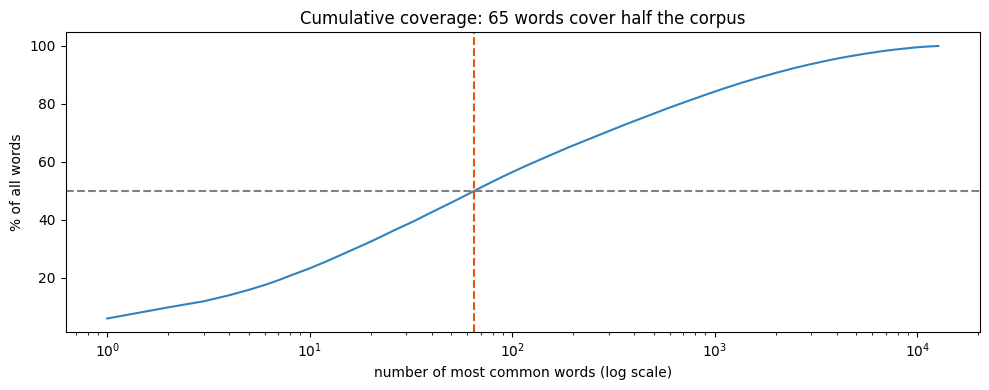

In [14]:
counts = pd.Series(freq).sort_values(ascending=False)
cum_share = counts.cumsum() / N
n_half = int((cum_share < 0.5).sum()) + 1

print(f"The {n_half} most common words make up half of all {N:,} words in the corpus.")
print(f"That is {n_half / V:.2%} of the {V:,} unique words.")
print("They are:", ", ".join(counts.index[:n_half]))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(1, V + 1), cum_share.values * 100, color="#3182bd")
ax.axhline(50, ls="--", color="gray"); ax.axvline(n_half, ls="--", color="#e6550d")
ax.set_xscale("log"); ax.set_xlabel("number of most common words (log scale)"); ax.set_ylabel("% of all words")
ax.set_title(f"Cumulative coverage: {n_half} words cover half the corpus")
plt.tight_layout(); plt.show()

## 4. The 200 highest-frequency words

In [15]:
top200 = pd.DataFrame({"word": counts.index[:200], "count": counts.values[:200]})
top200.index = np.arange(1, 201); top200.index.name = "rank"
top200["relative frequency"] = top200["count"] / N
top200["stopword"] = top200["word"].isin(STOP)

print(f"The top 200 words account for {top200['count'].sum() / N:.1%} of the corpus; "
      f"{top200.stopword.sum()} of them are stopwords.")

# show the 200 words compactly with a 4 side by side blocks of 50
blocks = [top200.iloc[i:i + 50][["word", "count"]].reset_index() for i in range(0, 200, 50)]
pd.concat(blocks, axis=1)

The top 200 words account for 65.7% of the corpus; 69 of them are stopwords.


,rank,word,count,rank,word,count,rank,word,count,rank,word,count
0,1,the,40252,51,two,2055,101,water,968,151,into,597
1,2,of,26131,52,did,2000,102,spent,968,152,took,587
2,3,to,14438,53,find,1947,103,third,968,153,square,583
3,4,a,14039,54,had,1933,104,apples,956,154,before,579
4,5,and,12788,55,be,1908,105,inches,948,155,used,577
5,6,in,11532,56,miles,1879,106,pieces,901,156,cards,573
6,7,is,11097,57,days,1872,107,pay,892,157,got,573
7,8,he,10793,58,after,1865,108,since,886,158,box,571
8,9,for,9066,59,hour,1852,109,remaining,886,159,ate,569
9,10,how,8166,60,because,1822,110,long,880,160,cars,569


## 5. Relative frequency of the top 200 words
The first chart shows each word's relative frequency (its share of all words) by rank, with every 5th word labeled. The second zooms in on the content words (non-stopwords) in the top 200, which reveal what these problems are about.

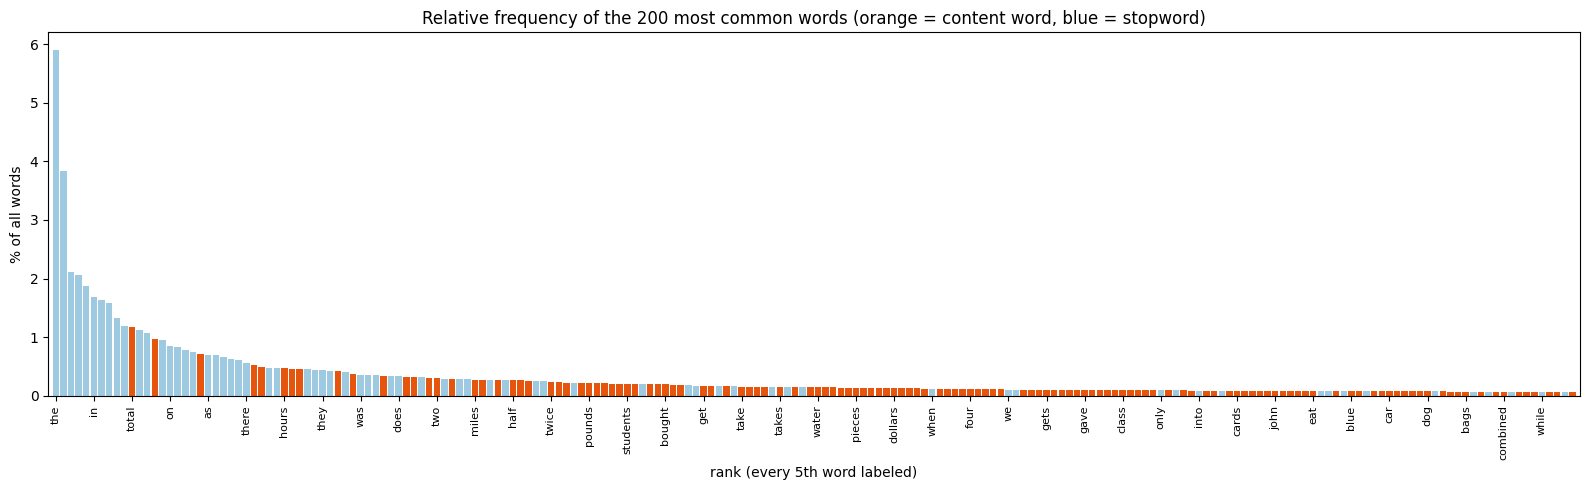

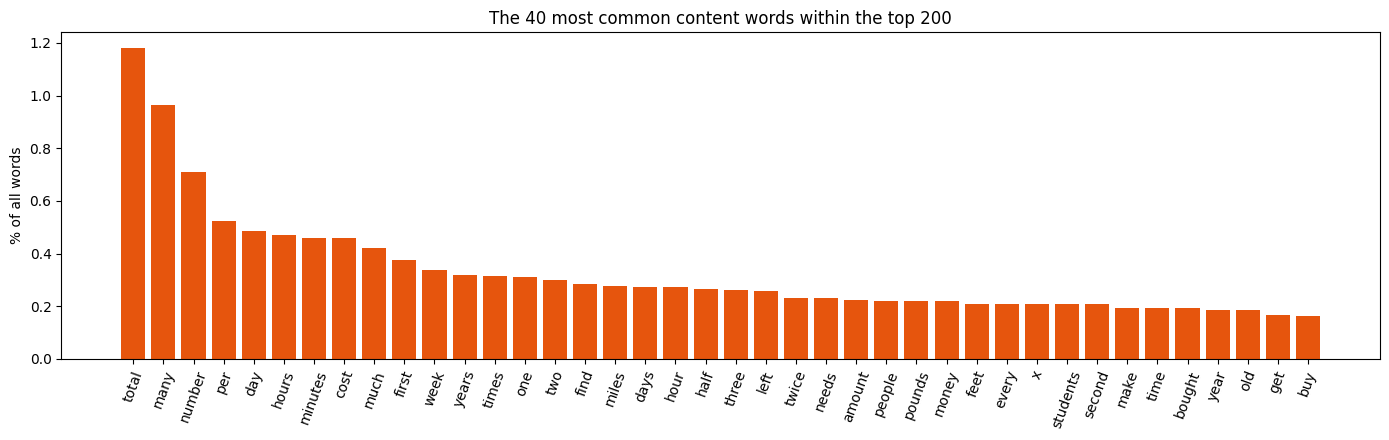

In [16]:
fig, ax = plt.subplots(figsize=(16, 5))
colors = np.where(top200["stopword"], "#9ecae1", "#e6550d")
ax.bar(top200.index, top200["relative frequency"] * 100, color=colors, width=0.85)
ax.set_xticks(top200.index[::5]); ax.set_xticklabels(top200["word"].iloc[::5], rotation=90, fontsize=8)
ax.set_xlim(0, 201); ax.set_ylabel("% of all words"); ax.set_xlabel("rank (every 5th word labeled)")
ax.set_title("Relative frequency of the 200 most common words (orange = content word, blue = stopword)")
plt.tight_layout(); plt.show()

content = top200[~top200.stopword].head(40)
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(content["word"], content["relative frequency"] * 100, color="#e6550d")
ax.set_ylabel("% of all words"); ax.tick_params(axis="x", rotation=70)
ax.set_title("The 40 most common content words within the top 200")
plt.tight_layout(); plt.show()

## 6. Does the relative frequency follow Zipf's law?
Zipf's law says that a word's frequency is inversely proportional to its rank: f(r) ∝ 1 / r^s with s ≈ 1. So the 2nd word should appear about half as often as the 1st, the 3rd about a third as often, and so on. On a log-log plot of frequency against rank, Zipf's law is a **straight line with slope -1**.

I check it in three ways:
1. A log-log plot of the observed frequencies against the ideal Zipf line.
2. A fitted slope s from a regression of log(frequency) on log(rank).
3. The product rank x relative frequency, which should be roughly constant if Zipf holds.

In [ ]:
ranks = np.arange(1, V + 1)
rel = counts.values / N

def zipf_slope(r, f):
    slope, intercept = np.polyfit(np.log10(r), np.log10(f), 1)
    pred = slope * np.log10(r) + intercept
    r2 = 1 - np.sum((np.log10(f) - pred) ** 2) / np.sum((np.log10(f) - np.log10(f).mean()) ** 2)
    return slope, intercept, r2

fits = []
for label, upto in [("Top 200 words", 200), ("Top 1,000 words", 1000), ("All words", V)]:
    s, b, r2 = zipf_slope(ranks[:upto], rel[:upto])
    fits.append({"range": label, "fitted slope": round(s, 3), "R²": round(r2, 3)})
display(pd.DataFrame(fits).set_index("range"))

s200, b200, _ = zipf_slope(ranks[:200], rel[:200])
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.loglog(ranks, rel, ".", ms=3, color="#3182bd", label="observed (all words)")
ax.loglog(ranks, rel[0] / ranks, "--", color="black", label="ideal Zipf: f(1) / r")
ax.loglog(ranks[:200], 10 ** b200 * ranks[:200] ** s200, color="#e6550d", lw=2, label=f"fit to top 200 (slope {s200:.2f})")
ax.axvline(200, color="gray", lw=0.8)
ax.set_xlabel("rank (log)"); ax.set_ylabel("relative frequency (log)"); ax.legend()
ax.set_title("Rank vs. frequency on log-log axes")

ax = axes[1]
rf = top200.index * top200["relative frequency"]
ax.plot(top200.index, rf, "o-", ms=3, color="#3182bd")
ax.axhline(np.median(rf), ls="--", color="gray", label="median")
ax.set_xlabel("rank"); ax.set_ylabel("rank × relative frequency"); ax.legend()
ax.set_title("Zipf check: rank × frequency should be roughly constant")
plt.tight_layout(); plt.show()

ratio = pd.DataFrame({"word": counts.index[:10], "observed": rel[:10], "Zipf prediction f(1)/r": rel[0] / ranks[:10]})
ratio["observed / predicted"] = ratio["observed"] / ratio["Zipf prediction f(1)/r"]
ratio.index = ranks[:10]
ratio.round(4)

,fitted slope,R²
range,,
Top 200 words,-0.959,0.982
"Top 1,000 words",-1.077,0.994
All words,-1.522,0.963


## 7. How does this corpus differ from "all words in all corpora"?
No corpus contains all words, so I use a standard stand-in for general English: the Brown Corpus, about 1 million words from 500 texts across 15 genres (news, fiction, science, religion, humor and more). I process it with the same tokenizer and compare relative frequencies. The ratio shows how many times more (or less) often a word appears in math word problems than in general English.

In [ ]:
brown_tokens = tokenize(" ".join(brown.words()))
bfreq = Counter(brown_tokens); NB = len(brown_tokens)
print(f"Brown corpus: {NB:,} words, {len(bfreq):,} unique words")
print(f"Vocabulary size at the same length ({N:,} words): GSM8K {V:,} vs. Brown {len(set(brown_tokens[:N])):,}")

comp = pd.DataFrame({"gsm8k count": pd.Series(freq), "brown count": pd.Series(bfreq)}).fillna(0)
comp["gsm8k per 10k"] = comp["gsm8k count"] / N * 1e4
comp["brown per 10k"] = comp["brown count"] / NB * 1e4
# Add-one smoothing so words missing from one corpus get a finite ratio
comp["ratio (gsm8k / brown)"] = ((comp["gsm8k count"] + 1) / (N + len(comp))) / ((comp["brown count"] + 1) / (NB + len(comp)))

top20_b = [w for w, _ in bfreq.most_common(20)]
top20_g = list(counts.index[:20])
print(f"\nWords shared by the two top-20 lists: {len(set(top20_b) & set(top20_g))} of 20")
print("In the GSM8K top 20 but not Brown's:", ", ".join(w for w in top20_g if w not in top20_b))
print("In Brown's top 20 but not GSM8K's:", ", ".join(w for w in top20_b if w not in top20_g))

cols = ["gsm8k per 10k", "brown per 10k", "ratio (gsm8k / brown)"]
print("\nMost OVER-represented in math word problems (words used 300+ times):")
display(comp[comp["gsm8k count"] >= 300].sort_values("ratio (gsm8k / brown)", ascending=False)[cols].head(20).round(2))
print("Most UNDER-represented in math word problems (common in Brown, 500+ uses, 3+ letters):")
display(comp[(comp["brown count"] >= 500) & (comp.index.str.len() >= 3)].sort_values("ratio (gsm8k / brown)")[cols].head(15).round(2))

In [ ]:
groups = {
    "quantity words (each, total, many, much, per)": ["each", "total", "many", "much", "per"],
    "operations (times, half, twice, more, less)": ["times", "half", "twice", "more", "less"],
    "money and time (dollars, cost, hours, minutes)": ["dollars", "cost", "costs", "hours", "minutes"],
    "he / she / his / her": ["he", "she", "his", "her"],
    "said": ["said"],
    "past-tense narration (was, had, were)": ["was", "had", "were"],
}
g = pd.DataFrame({k: [sum(freq[w] for w in v) / N * 1e4, sum(bfreq[w] for w in v) / NB * 1e4] for k, v in groups.items()},
                 index=["GSM8K math word problems", "Brown (general English)"]).T
ax = g.plot.barh(figsize=(10, 4.8), color=["#e6550d", "#9ecae1"])
ax.set_xlabel("uses per 10,000 words"); ax.set_title("The 'dialect' of math word problems vs. general English")
ax.invert_yaxis(); plt.tight_layout(); plt.show()
g.round(1)

### 7a. Bonus: questions vs. solutions
Inside the corpus, the student-facing questions and the teacher-style solutions use different words. The questions tell a short story, while the solutions are about calculating. Here are the words most typical of each part (compared with the other part, words used 100+ times).

In [ ]:
qf = Counter(t for toks in problems.q_tokens for t in toks); sf = Counter(t for toks in problems.s_tokens for t in toks)
NQ, NS = sum(qf.values()), sum(sf.values())
qs = pd.DataFrame({"question per 10k": pd.Series(qf) / NQ * 1e4, "solution per 10k": pd.Series(sf) / NS * 1e4}).fillna(0)
qs["ratio (question / solution)"] = ((pd.Series(qf).reindex(qs.index).fillna(0) + 1) / NQ) / ((pd.Series(sf).reindex(qs.index).fillna(0) + 1) / NS)
common = qs[(pd.Series(qf).reindex(qs.index).fillna(0) + pd.Series(sf).reindex(qs.index).fillna(0)) >= 100]

print(f"Question words: {NQ:,} ({len(qf):,} unique) | solution words: {NS:,} ({len(sf):,} unique)")
left = common.sort_values("ratio (question / solution)", ascending=False).head(12).round(2)
right = common.sort_values("ratio (question / solution)").head(12).round(2)
print("Most typical of the QUESTIONS:"); display(left)
print("Most typical of the SOLUTIONS:"); display(right)

a## Answers and conclusions

**1. Corpus.** GSM8K: 8,792 grade-school math word problems with human-written, step-by-step solutions.

**2. Unique words.** The corpus has **681,431 words** and **12,722 unique words**, where a word is a lowercased sequence of letters (internal apostrophes allowed, possessive 's removed, numbers excluded). The definition matters a lot:
- Splitting on spaces, case-sensitive, gives 44,189 "unique words", because every "$12," or "May." counts separately.
- Counting numbers as words would add 2,147 distinct numbers. Numbers make up 17% of everything in the text.
- Only **19%** of unique words appear just once. That share is low for a corpus this size: the vocabulary is small and repetitive.

**3. Half of the corpus.** The **65 most common words** make up half of all words, just **0.51%** of the vocabulary. Besides function words, that list already contains the core vocabulary of word problems: *how, total, many, each, number, per, day, hours, minutes, cost, much, more, than, times, half, twice, left, find*.

**4-5. Top 200.** The top 200 words cover **66%** of the corpus, and only 69 of them are stopwords. The most common content words are about quantity and measurement: *total, many, number, per, day, hours, minutes, cost, much, times, half, twice, left, amount, money, pounds, feet, miles*. The everyday objects of word problems appear too: *students, apples, cookies, water, pages*.

**6. Zipf's law: approximately, but less cleanly than in natural texts.**
- **The top 200 words fit well.** The fitted log-log slope is **-0.96** (R² = 0.98), close to Zipf's -1, and rank x frequency stays roughly constant (about 0.12 to 0.16) from rank 20 to rank 200.
- **The very top is too flat.** Words ranked 2 to 10 appear **1.1 to 2.1 times** more often than f(1)/r predicts. "The" is less dominant than Zipf expects, and "he", "for" and "how" are about twice as common as predicted. Rank x frequency climbs from 0.06 to 0.14 over the first 20 ranks.
- **The tail is too steep.** Across all words the slope is **-1.52**, and beyond rank 5,000 the curve falls below the Zipf line. There are far fewer rare words than Zipf predicts. Word problems reuse a controlled vocabulary, much like a textbook.

**7. How this corpus differs from "all words in all corpora".** Compared with the Brown Corpus (1 million words of general American English):
- **It is a small, specialized vocabulary.** At the same length (681,000 words), Brown has **34,371** unique words and GSM8K only **12,722**, about a third as many.
- **It is about quantities.** Quantity words (*each, total, many, much, per*) are **12 times** more common, and money and time words (*dollars, cost, hours, minutes*) are **19 times** more common. Half of the GSM8K top 20 is not in Brown's: *how, total, she, has, many, each, are, if, so, number*.
- **Its "story" nouns are the props of a math class.** The most over-represented frequent words are units and countable objects: kg (542x), slices (271x), marbles (249x), ounces, apples, shirts, liters, cookies, gallons, pizza, pencils, and money verbs like *earns, spends, buys*.
- **It is written in the present tense with simple characters.** "He / she / his / her" are almost **twice** as common as in Brown, because every problem has a named character (*he* 10,793 times, *she* 7,615). But past-tense narration (*was, had, were*) is half as common, and *said* is about 29 times rarer. Abstract and opinion words almost disappear: *world, great, general, thought, might, never, our*.
- **Questions and solutions have different dialects.** The questions are a story ending in a question (*does, did, how, what, many, much, decides*). The solutions use the language of reasoning (*thus, therefore, means, hence, let, we*), arithmetic operations (*multiply, subtract, equation*) and the variable *x*.

A small set of signal words (*total, each, per, twice, half, left, more than*) carries the math in these problems. These are exactly the words students need to decode, which supports teaching that vocabulary explicitly, alongside the arithmetic.

**Limitations.** GSM8K was written by a small group of problem writers for testing AI models, so it may be more uniform than real textbooks. Brown is a 1961 corpus and only one sample of general English. Excluding numbers is a choice: with numbers counted as words, the vocabulary and Zipf tail would look different.
